Cell 1 – Imports and paths

In [1]:
from pathlib import Path
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------
# Adjust this to your unfolded output root (same as before)
# ------------------------------------------------------------------
LOCAL_ROOT = '/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/'
GRID_ROOT  = '/rs/rs_grp_mljet/'

# Original unfolded dataset root
OUTPUT_ROOT = Path(f"{LOCAL_ROOT}ml-jet-ext/pTHat50-250_eCM5020_c0005_pT90-110_R0p4").expanduser()
METADATA_DIR = OUTPUT_ROOT / "metadata"

# Aggregated dataset root
AGG_OUTPUT_ROOT = Path(f"{LOCAL_ROOT}ml-jet-ext/pTHat50-250_eCM5020_c0005_pT90-110_R0p4_agg500").expanduser()
AGG_OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# NEW: metadata for aggregated dataset
AGG_METADATA_DIR = AGG_OUTPUT_ROOT / "metadata"
AGG_METADATA_DIR.mkdir(parents=True, exist_ok=True)

print("OUTPUT_ROOT:", OUTPUT_ROOT)
print("METADATA_DIR:", METADATA_DIR)
print("AGG_OUTPUT_ROOT:", AGG_OUTPUT_ROOT)
print("AGG_METADATA_DIR:", AGG_METADATA_DIR)
assert METADATA_DIR.exists(), "METADATA_DIR does not exist"


OUTPUT_ROOT: /mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_c0005_pT90-110_R0p4
METADATA_DIR: /mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_c0005_pT90-110_R0p4/metadata
AGG_OUTPUT_ROOT: /mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_c0005_pT90-110_R0p4_agg500
AGG_METADATA_DIR: /mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_c0005_pT90-110_R0p4_agg500/metadata


Cell 2 – Log normalization helper

In [2]:
def log_normalize_image(img, epsilon=1e-8, img_max=1.0):
    """
    Apply log-based normalization:

        I_log = (log(I + eps) - log(eps)) / (log(img_max + eps) - log(eps))

    Then clip to [0,1].
    Assumes img is non-negative. If img_max <= 0, returns zeros.
    """
    I = np.asarray(img, dtype=np.float32)
    if img_max <= 0:
        return np.zeros_like(I, dtype=np.float32)

    num = np.log(I + epsilon) - math.log(epsilon)
    den = math.log(img_max + epsilon) - math.log(epsilon)
    if den <= 0:
        return np.zeros_like(I, dtype=np.float32)

    I_log = num / den
    return np.clip(I_log, 0.0, 1.0)


Cell 3 – Pick one config and inspect jets CSV

In [3]:
# Pick a single config to test
CONFIG_NAME = "c0005_alpha0p20_q_1p0_unfolded"  # change if you want another

jets_csv = METADATA_DIR / f"{CONFIG_NAME}_jets.csv"
print("jets_csv:", jets_csv)
df = pd.read_csv(jets_csv)
df.head()


jets_csv: /mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_c0005_pT90-110_R0p4/metadata/c0005_alpha0p20_q_1p0_unfolded_jets.csv


,file_paths,alpha,q0,seed,phi_min,phi_max,eta_min,eta_max,pT_min,pT_max
0,c0005_alpha0p20_q_1p0_unfolded/seed_000/event_...,0.2,1.0,0,-0.158116,0.003028,-0.185676,0.094188,0.387301,74.265800
1,c0005_alpha0p20_q_1p0_unfolded/seed_000/event_...,0.2,1.0,0,-0.078756,0.086337,-0.068949,0.150243,0.159525,25.231600
2,c0005_alpha0p20_q_1p0_unfolded/seed_000/event_...,0.2,1.0,0,-0.198606,0.137627,-0.187145,0.156072,0.493807,14.279500
3,c0005_alpha0p20_q_1p0_unfolded/seed_000/event_...,0.2,1.0,0,-0.028445,0.060635,-0.048635,0.067555,0.156588,21.506500
4,c0005_alpha0p20_q_1p0_unfolded/seed_000/event_...,0.2,1.0,0,-0.068856,0.092010,-0.051399,0.049757,0.340197,24.092199


Cell 4 – Check counts and determine label columns

In [4]:
len_df = len(df)
print(f"{CONFIG_NAME}: {len_df} jets total")

# Parameters
GROUP_SIZE = 500
N_AGG_TEST = 4    # small number for testing; later we’ll use N_AGG = 400
MAX_PT = 110.0
EPSILON = 1e-8
RNG_SEED = 0

required = N_AGG_TEST * GROUP_SIZE
print("Required jets for test:", required)

assert len_df >= required, f"Not enough jets for test: need {required}, have {len_df}"

# Columns that are NOT labels (technical columns)
drop_cols = {
    "file_paths",
    "phi_min",
    "phi_max",
    "eta_min",
    "eta_max",
    "pT_min",
    "pT_max",
    "seed",
}
label_cols = [c for c in df.columns if c not in drop_cols]
print("Label columns:", label_cols)


c0005_alpha0p20_q_1p0_unfolded: 221933 jets total
Required jets for test: 2000
Label columns: ['alpha', 'q0']


Cell 5 – Build test groups of indices

In [5]:
rng = np.random.RandomState(RNG_SEED)

# Random permutation of all indices
perm = rng.permutation(len_df)
used_indices = perm[:required]

# Reshape into (N_AGG_TEST, GROUP_SIZE)
groups = used_indices.reshape(N_AGG_TEST, GROUP_SIZE)
groups.shape


(4, 500)

Cell 6 – Process ONE group: load 500 jets, aggregate, normalize, log-normalize, plot

In [6]:
group_idx = 0  # pick which group to test
idx_group = groups[group_idx]
df_group = df.iloc[idx_group]

print(f"Group {group_idx}: {len(df_group)} jets")

imgs = []
src_paths = []

for _, row in df_group.iterrows():
    rel_path = row["file_paths"]
    img_path = OUTPUT_ROOT / rel_path
    if not img_path.exists():
        raise FileNotFoundError(f"Missing jet .npy file: {img_path}")
    arr = np.load(img_path).astype(np.float32)
    imgs.append(arr)
    src_paths.append(rel_path)

imgs = np.stack(imgs, axis=0)
print("imgs shape:", imgs.shape)  # (500, H, W)

# Mean and normalization
mean_img = imgs.mean(axis=0)         # (H, W)
mean_norm = mean_img / MAX_PT       # normalized by 110
mean_log = log_normalize_image(mean_norm, epsilon=EPSILON, img_max=1.0)

print("mean_img min/max:", float(mean_img.min()), float(mean_img.max()))
print("mean_norm min/max:", float(mean_norm.min()), float(mean_norm.max()))
print("mean_log min/max:", float(mean_log.min()), float(mean_log.max()))


Group 0: 500 jets
imgs shape: (500, 32, 32)
mean_img min/max: 0.0 14.897016525268555
mean_norm min/max: 0.0 0.13542743027210236
mean_log min/max: 0.0 0.8914633393287659


Cell 7 – Quick visualization of the test aggregate

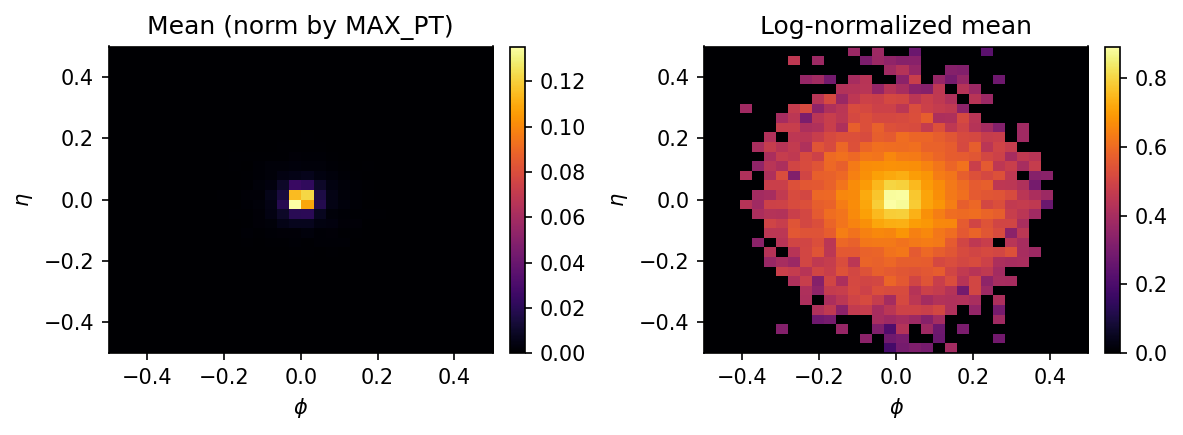

In [7]:
PHI_RANGE = (-0.5, 0.5)
ETA_RANGE = (-0.5, 0.5)
phi_min, phi_max = PHI_RANGE
eta_min, eta_max = ETA_RANGE

fig, axes = plt.subplots(1, 2, figsize=(8, 3), dpi=150)

# Linear normalized mean
ax = axes[0]
im0 = ax.imshow(
    mean_norm.T,
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    aspect="auto",
    cmap="inferno",
    # interpolation="nearest",
)
ax.set_title("Mean (norm by MAX_PT)")
ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$\eta$")
fig.colorbar(im0, ax=ax, fraction=0.046, pad=0.04)

# Log-normalized
ax = axes[1]
im1 = ax.imshow(
    mean_log.T,
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    aspect="auto",
    cmap="inferno",
    interpolation="nearest",
)
ax.set_title("Log-normalized mean")
ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$\eta$")
fig.colorbar(im1, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()


Cell 8 – Loop over ALL groups for this config (still with N_AGG_TEST)

In [8]:
# Where original jets live (for reading)
config_dir = OUTPUT_ROOT / CONFIG_NAME

# Where aggregated jets will be saved (same structure, different root, no seed subdirs)
agg_config_dir = AGG_OUTPUT_ROOT / CONFIG_NAME
agg_config_dir.mkdir(parents=True, exist_ok=True)

agg_rows = []

for agg_idx, idx_group in enumerate(groups):
    df_group = df.iloc[idx_group]

    imgs = []
    src_paths = []

    for _, row in df_group.iterrows():
        rel_path = row["file_paths"]
        img_path = OUTPUT_ROOT / rel_path
        if not img_path.exists():
            raise FileNotFoundError(f"Missing jet .npy file: {img_path}")
        arr = np.load(img_path).astype(np.float32)
        imgs.append(arr)
        src_paths.append(rel_path)

    imgs = np.stack(imgs, axis=0)
    mean_img = imgs.mean(axis=0)
    mean_norm = mean_img / MAX_PT
    mean_log = log_normalize_image(mean_norm, epsilon=EPSILON, img_max=1.0)

    # Save aggregated image
    agg_fname = f"agg500_event_{agg_idx:07d}.npy"
    agg_path = agg_config_dir / agg_fname
    np.save(agg_path, mean_log)

    # Path to save in metadata: relative to AGG_OUTPUT_ROOT
    agg_rel = agg_path.relative_to(AGG_OUTPUT_ROOT)

    # Labels: from first row (config-constant columns)
    label_values = {}
    if label_cols:
        first_row = df_group.iloc[0]
        label_values = {col: first_row[col] for col in label_cols}

    agg_rows.append(
        {
            "config": CONFIG_NAME,
            "agg_file_path": str(agg_rel),
            "source_file_paths": "|".join(src_paths),
            **label_values,
        }
    )

    print(f"[TEST] {CONFIG_NAME}: built aggregate {agg_idx+1}/{N_AGG_TEST}")


[TEST] c0005_alpha0p20_q_1p0_unfolded: built aggregate 1/4
[TEST] c0005_alpha0p20_q_1p0_unfolded: built aggregate 2/4
[TEST] c0005_alpha0p20_q_1p0_unfolded: built aggregate 3/4
[TEST] c0005_alpha0p20_q_1p0_unfolded: built aggregate 4/4


Cell 9 – Inspect and optionally save the per-config agg500 metadata (test)

In [9]:
agg_df = pd.DataFrame(agg_rows)
display(agg_df.head())

# Save per-config aggregated metadata in the aggregated root's metadata dir
agg_meta_path = AGG_METADATA_DIR / f"{CONFIG_NAME}_agg500_metadata.csv"
agg_df.to_csv(agg_meta_path, index=False)

print(f"[INFO] Saved aggregated metadata for {CONFIG_NAME} to {agg_meta_path}")


,config,agg_file_path,source_file_paths,alpha,q0
0,c0005_alpha0p20_q_1p0_unfolded,c0005_alpha0p20_q_1p0_unfolded/agg500_event_00...,c0005_alpha0p20_q_1p0_unfolded/seed_092/event_...,0.2,1.0
1,c0005_alpha0p20_q_1p0_unfolded,c0005_alpha0p20_q_1p0_unfolded/agg500_event_00...,c0005_alpha0p20_q_1p0_unfolded/seed_038/event_...,0.2,1.0
2,c0005_alpha0p20_q_1p0_unfolded,c0005_alpha0p20_q_1p0_unfolded/agg500_event_00...,c0005_alpha0p20_q_1p0_unfolded/seed_015/event_...,0.2,1.0
3,c0005_alpha0p20_q_1p0_unfolded,c0005_alpha0p20_q_1p0_unfolded/agg500_event_00...,c0005_alpha0p20_q_1p0_unfolded/seed_186/event_...,0.2,1.0


[INFO] Saved aggregated metadata for c0005_alpha0p20_q_1p0_unfolded to /mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_c0005_pT90-110_R0p4_agg500/metadata/c0005_alpha0p20_q_1p0_unfolded_agg500_metadata.csv


In [10]:
#get the third cell of the first row agg_df then split it by pipe character
# agg_df.iloc[0,2]
img_paths=agg_df.iloc[0,2].split("|")
print(len(img_paths))
agg_file_path=agg_df.iloc[0,1]
print("Aggregate file path:", agg_file_path)

500
Aggregate file path: c0005_alpha0p20_q_1p0_unfolded/agg500_event_0000000.npy
